---
tags: [algorithm, chemistry, variational]
---

# An Adaptive Variational Algorithm for Exact Molecular Simulations

Quantum simulation of chemical systems is attracting attention as a near-term application of quantum computers.
The variational quantum eigensolver (VQE) is a well-known method for molecular simulation on quantum hardware.
However, its results depend strongly on the wavefunction ansatz chosen in advance.
To address this limitation, [Grimsley et al. (2019)](https://www.nature.com/articles/s41467-019-10988-2) proposed a method that constructs an ansatz by adding operators one at a time according to the molecule being studied, instead of fixing the ansatz in advance.
This approach can produce ansätze with fewer parameters and shallower circuits.
In this tutorial, we will implement the proposed method, ADAPT-VQE, using Qamomile.

In [1]:
from itertools import combinations, product

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from qiskit_aer.primitives import EstimatorV2

from openfermion import (
    FermionOperator,
    commutator,
    hermitian_conjugated,
    jordan_wigner,
    normal_ordered,
)
from openfermion.chem import MolecularData
from openfermion.transforms import get_fermion_operator
from openfermionpyscf import run_pyscf

import qamomile.circuit as qmc
import qamomile.observable as qmo
from qamomile.qiskit import QiskitTranspiler
from qamomile.qiskit.transpiler import QiskitExecutor

Matplotlib is building the font cache; this may take a moment.


## Background

### Quantum Chemistry Calculations and VQE

When calculating molecular states, the space needed to represent the electronic state grows exponentially with the number of orbitals.
This limits quantum chemistry calculations on classical computers, and quantum computing is expected to overcome these limitations.
Achieving this requires efficient quantum algorithms as well as capable quantum computers with enough high-quality qubits.
VQE has attracted attention as one such approach.
It performs state preparation and measurements on a quantum computer, while updating parameters classically.
Although it requires many measurements, its shallow circuits make it suitable for execution on NISQ devices.
However, the accuracy of VQE depends on the expressive power of its ansatz.
Approaches such as hardware-efficient ansätze have been explored to improve this, but accurately calculating strongly correlated systems remains difficult.
To address this challenge, [Grimsley et al. (2019)](https://www.nature.com/articles/s41467-019-10988-2) proposed ADAPT-VQE, which constructs an ansatz for the molecule being studied instead of fixing it in advance.

### Previous Work: Adaptive Coupled Cluster Theory (@CC)

Before explaining ADAPT-VQE, let us briefly introduce an important earlier classical method proposed by [Lyakh & Bartlett (2010)](https://pubs.aip.org/aip/jcp/article-abstract/133/24/244112/983180/An-adaptive-coupled-cluster-theory-CC-approach?redirectedFrom=fulltext).
To calculate a molecule's electronic state, we start from the state $\vert \Phi_\mathrm{HF} \rangle$ obtained using the Hartree–Fock method.
Coupled cluster (CC) theory applies the following operator to this state:

$$
\vert \Psi_\mathrm{CC} \rangle 
= e^T \vert \Phi_\mathrm{HF} \rangle \tag{1}
$$

Here,

$$
T 
= T_1 + T_2 + \cdots 
= \sum_{i, a} t_{ia} a_a^\dagger a_i + \frac{1}{4} \sum_{i, j, a, b} t_{ij}^{ab} a_a^\dagger a_b^\dagger a_j a_i + \cdots \tag{2}
$$

is the excitation operator, where $T_1$ represents single-electron excitations, $T_2$ represents two-electron excitations, and so on.
The operators $a_p^\dagger, a_p$ create and annihilate an electron in orbital $p$, respectively.
Coupled cluster theory can thus be viewed as incorporating excitation operators through an exponential.
The method is called CCS when only single excitations are included, CCSD when excitations up to doubles are included, CCSDT when excitations up to triples are included, and so on.
Conventional CC methods improve accuracy by increasing the excitation rank treated independently, following the sequence CCS -> CCSD -> CCSDT.
However, this approach includes every term at each rank, even those that contribute little, so it requires handling a large number of amplitudes.
The @CC method instead adds only excitations considered important.
If $S$ denotes the set of selected excitations, the calculation can be defined by

$$
T_S 
= \sum_{\mu \in S} t_\mu \tau_\mu, \quad
\vert \Psi_S \rangle 
= e^{T_S} \vert \Phi_\mathrm{HF} \rangle \tag{3}
$$

This specifies the model to be calculated.
For example, one could use

$$
T_S 
= T_1 + T_2 + \sum_{\mu \in S_3} t_\mu \tau_\mu + \sum_{\nu \in S_4} t_\nu \tau_\nu \tag{4}
$$

as the cluster operator.  
In this case, both the set $S$, which determines which amplitudes are included, and the values of the selected amplitudes $t_\mu$ must be adjusted.
The @CC method uses an importance function to select the cluster amplitudes needed to describe the target electronic state.
Its aim is to construct a computational model suited to the problem, instead of including all excitation operators uniformly.

## Proposed Method

### ADAPT-VQE 

Let us now take a closer look at ADAPT-VQE.
As in @CC, the starting point is the Hartree–Fock state $\vert \Phi_\mathrm{HF} \rangle$.
Recall that CCSD expresses the state as $\vert \Psi_\mathrm{CCSD} \rangle = e^{T_1 + T_2} \vert \Phi_\mathrm{HF} \rangle$.
To prepare this state with a quantum circuit, we need to consider unitary CCSD (UCCSD).
We therefore define

$$
K 
= T_1 - T_1^\dagger + T_2 - T_2^\dagger 
= A_1 + A_2 \quad (A_1 \equiv T_1 - T_1^\dagger, A_2 \equiv T_2 - T_2^\dagger) \tag{5}
$$

and use it to construct the state through a unitary transformation:

$$
\lvert \Psi_\mathrm{UCCSD} \rangle
= e^K \vert \Phi_\mathrm{HF} \rangle \tag{6}
$$

This gives the UCCSD state.
Indeed, $K^\dagger = - K$, so $e^K$ is unitary because $(e^K)^\dagger e^K = e^{-K} e^K = I$.  
Conventional single and double excitations distinguish between occupied orbitals $i, j$ and unoccupied orbitals $a, b$ in the Hartree–Fock state.
The generalized operators introduced in ADAPT-VQE, however, do not restrict orbital combinations according to whether the orbitals are occupied or unoccupied in the Hartree–Fock state.
This allows the candidate set to include operators that give zero when applied directly to the reference Hartree–Fock state.
So far, we have considered CCSD; more generally, the state used in ADAPT-VQE is written as $\vert \Psi_\mathrm{UCCSD} \rangle = e^{\sum_\mu \theta_\mu A_\mu} \vert \Phi_\mathrm{HF} \rangle$.
Here, $\theta_\mu$ is a parameter that determines the weight of each operator.
To represent this with a quantum circuit, let us construct it as a product of individual unitary transformations.
Specifically,

$$
\vert \Psi_\mathrm{ADAPT} \rangle 
= e^{\theta_L A_{\mu_L}} e^{\theta_{L-1} A_{\mu_{L-1}}} \cdots e^{\theta_2 A_{\mu_2}} e^{\theta_1 A_{\mu_1}} \vert \Phi_\mathrm{HF} \rangle \tag{7}
$$

constructs the ansatz in a manner resembling a Trotter decomposition.
Note, however, that unlike the usual Trotter decomposition $e^{A + B} = \lim_{r \rightarrow \infty} (e^{A/r} e^{B/r})^r$, the same coefficients are not used throughout.

### Constructing the Operator Pool and Selecting Operators

As described above, the basic building blocks combine single and double electron excitations with their Hermitian conjugates, which represent de-excitations.
For a single excitation, the operator is

$$
A_{pq} 
=  a_p^\dagger a_q - a_q^\dagger a_p \tag{8}
$$

This combines the excitation and de-excitation terms.
For a double excitation, we use

$$
B_{pqrs} 
= a_p^\dagger a_q^\dagger a_r a_s, \qquad 
A_{pqrs} 
= B_{pqrs} - B_{pqrs}^\dagger \tag{9}
$$

which has the same structure.  
ADAPT-VQE uses the operators in Eqs. (8) and (9) to prepare a pool of candidates $\mathcal{P} = \{A_1, A_2, \dots, A_\mu, \dots, A_M\}$ for constructing the circuit.
For example, suppose that $A_3$ is selected first, followed by $A_8$, and finally $A_2$.
The resulting state is $\vert \Psi (\boldsymbol{\theta}) \rangle = e^{\theta_3 A_2} e^{\theta_2 A_8} e^{\theta_1 A_3} \vert \Phi_\mathrm{HF} \rangle$.
Selected operators remain in the pool and may be selected again in later iterations.
To determine which operator to apply next, let $\vert \Psi^{(k)} \rangle$ denote the state obtained after adding $k$ operators and optimizing their parameters.
The state obtained by appending a candidate operator $A_\mu$ and its energy are

$$
\vert \Psi (\alpha) \rangle 
= e^{\alpha A_\mu} \vert \Psi^{(k)} \rangle, \qquad 
E_\mu (\alpha) 
= \langle \Psi^{(k)} \vert e^{-\alpha A_\mu} H e^{\alpha A_\mu} \vert \Psi^{(k)} \rangle \tag{10}
$$

respectively.
We now calculate the gradient at $\alpha = 0$, before the appended operator changes the state.
This gives

$$
g_\mu 
= \left. \frac{dE_\mu (\alpha)}{d\alpha} \right\vert_{\alpha = 0} 
= \left. \langle \Psi^{(k)} \vert (-A_\mu e^{-\alpha A_\mu} H e^{\alpha A_\mu} + e^{-\alpha A_\mu} H A_\mu e^{\alpha A_\mu}) \vert \Psi^{(k)} \rangle \right\vert_{\alpha = 0}
= \langle \Psi^{(k)} \vert (-A_\mu H + H A_\mu) \vert \Psi^{(k)} \rangle 
= \langle \Psi^{(k)} \vert [H, A_\mu] \vert \Psi^{(k)} \rangle \tag{11}
$$

Using these gradients $g_\mu$, we select the operator $A_{\mu^\ast}$ with the largest absolute gradient.
Even when the gradient is positive, the corresponding parameter $\theta_{k+1}$ can be made negative, so selection depends only on the magnitude of the gradient.
This criterion measures how readily the energy can improve near the current state $\vert \Psi^{(k)} \rangle$.
It does not exhaustively search for the operator that would produce the largest energy reduction after it is added and all parameters are optimized.  
We append the selected operator to obtain the ansatz $\vert \Psi^{(k+1)} (\boldsymbol{\theta}) \rangle = e^{\theta_{k+1} A_{\mu^\ast}} e^{\theta_{k} A_{\mu_k}} e^{\theta_{k-1} A_{\mu_{k-1}}} \cdots e^{\theta_{1} A_{\mu_{1}}} \vert \Phi_\mathrm{HF} \rangle$, then run conventional VQE to solve

$$
\min_{\theta_1, \theta_2, \dots, \theta_{k+1}} \langle \Psi^{(k+1)} (\boldsymbol{\theta}) \vert H \vert \Psi^{(k+1)} (\boldsymbol{\theta}) \rangle \tag{12}
$$

for the minimum energy.
All parameters $\theta_{k+1}, \theta_k, \dots, \theta_1$ associated with the operators added so far are optimized.
For the VQE calculation at step $k + 1$, we initialize the parameters as $\boldsymbol{\theta}_\mathrm{initial} = (\boldsymbol{\theta}^\ast, 0)$, using the optimized parameters $\boldsymbol{\theta}^\ast$ from step $k$.
The initial value of $\theta_{k+1}$, the parameter for the operator $A_{\mu^\ast}$ newly added at step $k+1$, is zero.
Since $e^{0 A_{\mu^\ast}} = I$, the state immediately after adding the operator is identical to the optimized state from step $k$.
Initializing $\theta_{k+1}$ to zero therefore naturally embeds the previous solution in the new ansatz.

## Implementation with Qamomile

Let us now implement ADAPT-VQE with Qamomile.

### Setting Up the Molecule

We will calculate the energy of the $\mathrm{H}_2$ molecule.
Specify the internuclear distances at which to evaluate the energy, in angstroms.

In [2]:
# Internuclear distances R [Å]. Run the cells in order; adjust this array as needed.
bond_lengths = np.array([0.25, 0.50, 0.75, 1.0, 1.25, 1.5, 1.75, 2.00])
basis = "sto-3g"

gradient_threshold = 1e-3  # Threshold for the normalized operator pool
max_adapt_steps = 6         # Maximum number of operators to add at each distance
max_vqe_iterations = 120    # Maximum BFGS iterations after each operator addition

assert bond_lengths.ndim == 1 and len(bond_lengths) >= 2
assert np.all(bond_lengths > 0)
assert np.all(np.diff(bond_lengths) > 0), "Distances must be strictly increasing with no duplicates"
print("Distances to evaluate [Å]:", bond_lengths.tolist())
print("Number of points:", len(bond_lengths))

Distances to evaluate [Å]: [0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
Number of points: 8


### Determining the Number of Qubits

In the STO-3G basis, $\mathrm{H}_2$ has two spatial orbitals, four spin orbitals, and two electrons.
As long as we use the same basis, the number of qubits and electrons does not change with the distance, so we only need to construct the operator pool once.
We therefore create a molecular model at the smallest distance specified above and determine the required number of qubits.

In [3]:
first_R = float(bond_lengths[0])
first_geometry = [["H", [0.0, 0.0, 0.0]], ["H", [0.0, 0.0, first_R]]]
first_molecule = MolecularData(first_geometry, basis, multiplicity=1, charge=0)
first_molecule = run_pyscf(first_molecule, run_scf=True, run_fci=True)

n_qubits = first_molecule.n_qubits
n_electrons = first_molecule.n_electrons
n_spatial = n_qubits // 2

assert n_qubits == 4 and n_electrons == 2
print(f"Qubits: {n_qubits}, Electrons: {n_electrons}, Spatial orbitals: {n_spatial}")
print(f"R={first_R:.2f} Å: HF={first_molecule.hf_energy:.10f} Ha, "
      f"FCI={first_molecule.fci_energy:.10f} Ha")

Qubits: 4, Electrons: 2, Spatial orbitals: 2
R=0.25 Å: HF=-0.3050005338 Ha, FCI=-0.3122699027 Ha


### Enumerating Generalized Single and Double Excitations

We consider generalized combinations of spatial orbitals, rather than restricting excitations to transitions from occupied to unoccupied Hartree–Fock orbitals.
Here, we construct a simplified pool of fermionic operators for $\mathrm{H}_2$.

In [4]:
raw_pool = []

# Spin-complemented generalized single excitations.
for p, q in combinations(range(n_spatial), 2):
    T = (
        FermionOperator(((2*q, 1), (2*p, 0)))
        + FermionOperator(((2*q+1, 1), (2*p+1, 0)))
    )
    raw_pool.append((f"Single excitation({p}->{q})", T))

# Opposite-spin double excitations and their spin-exchanged counterparts.
for p, q, r, s in product(range(n_spatial), repeat=4):
    T = (
        FermionOperator(((2*r, 1), (2*s+1, 1), (2*q+1, 0), (2*p, 0)))
        + FermionOperator(((2*r+1, 1), (2*s, 1), (2*q, 0), (2*p+1, 0)))
    )
    raw_pool.append((f"Double excitation_ab({p},{q}->{r},{s})", T))

# Same-spin double excitations and their spin-exchanged counterparts.
for p, q in combinations(range(n_spatial), 2):
    for r, s in combinations(range(n_spatial), 2):
        T = (
            FermionOperator(((2*r, 1), (2*s, 1), (2*q, 0), (2*p, 0)))
            + FermionOperator(((2*r+1, 1), (2*s+1, 1), (2*q+1, 0), (2*p+1, 0)))
        )
        raw_pool.append((f"Double excitation_same({p},{q}->{r},{s})", T))

print("Number of candidates before deduplication:", len(raw_pool))

Number of candidates before deduplication: 18


### Anti-Hermitian Operators, Normalization, and Deduplication

From each excitation operator $T_\mu$ constructed above, we form $A_\mu = T_\mu - T_\mu^\dagger$.
We then normalize its coefficient norm to one.
Since $A_\mu$ and $- A_\mu$ can be implemented by reversing the sign of the same parameter, we remove these duplicates.

In [5]:
pool = []
pool_labels = []
seen = set()

for label, T in raw_pool:
    A = normal_ordered(T - hermitian_conjugated(T))
    A.compress()
    norm = np.sqrt(sum(abs(c)**2 for c in A.terms.values()))
    if norm < 1e-12:
        continue

    A = A / norm
    first_coeff = sorted(A.terms.items())[0][1]
    if first_coeff.real < 0:
        A = -A

    key = tuple(
        (term, round(float(coeff.real), 10), round(float(coeff.imag), 10))
        for term, coeff in sorted(A.terms.items())
    )
    if key in seen:
        continue
    seen.add(key)
    pool.append(A)
    pool_labels.append(label)

print("Operator pool size after deduplication:", len(pool))
for j, label in enumerate(pool_labels):
    print(f"{j:2d}: {label}")
assert len(pool) > 0

Operator pool size after deduplication: 4
 0: Single excitation(0->1)
 1: Double excitation_ab(0,0->0,1)
 2: Double excitation_ab(0,0->1,1)
 3: Double excitation_ab(0,1->1,1)


### Converting to Observables

We apply the Jordan–Wigner transformation to the generator $G_\mu = i A_\mu$ that appears in the exponent.
Using the transformed generator, we implement $e^{-i\theta G_\mu} \ (=e^{\theta A_\mu})$.

In [6]:
# Apply the Jordan-Wigner transformation to G_mu = i*A_mu for the generalized H2 excitations.
# The generators used from this cell onward do not depend on the distance R.
pauli_factories = {"X": qmo.X, "Y": qmo.Y, "Z": qmo.Z}
generators = []

for A in pool:
    op = jordan_wigner(1j * A)
    obs = qmo.Hamiltonian()
    for term, coeff in op.terms.items():
        if abs(coeff.imag) > 1e-8:
            raise ValueError(f"A complex coefficient remains in the generator: {coeff}")
        value = float(coeff.real)
        if abs(value) < 1e-12:
            continue
        if len(term) == 0:
            obs.constant += value
        else:
            pauli_product = qmo.Hamiltonian()
            pauli_product.constant = 1.0
            for qubit_index, symbol in term:
                pauli_product *= pauli_factories[symbol](qubit_index)
            obs += value * pauli_product
    generators.append(obs)

M = len(pool)
assert len(generators) == M and M > 0
print(f"Operator pool size: {M}")

Operator pool size: 4


### Creating a Qamomile Quantum Kernel

Let us create a quantum kernel that prepares the Hartree–Fock state $\vert \Phi_\mathrm{HF} \rangle$, applies the selected generators $G_\mu$ in sequence, and returns the expectation value of a specified observable.
Passing $H$ as `observable` gives the energy.
Passing $[H, A_\mu]$ instead gives the gradient used for operator selection.

In [7]:
@qmc.qkernel
def adapt_vqe_kernel(
    n: qmc.UInt,
    n_electrons: qmc.UInt,
    n_layers: qmc.UInt,
    operators: qmc.Vector[qmc.Observable],
    thetas: qmc.Vector[qmc.Float],
    observable: qmc.Observable,
) -> qmc.Float:
    q = qmc.qubit_array(n, name="q")
    for i in qmc.range(n_electrons):
        q[i] = qmc.x(q[i])  # Occupy the Hartree–Fock orbitals
    for i in qmc.range(n_layers):
        q = qmc.pauli_evolve(q, operators[i], thetas[i])
    return qmc.expval(q, observable)

### Running ADAPT-VQE at Each Distance

We are now ready to run ADAPT-VQE at each distance.
For each distance `R`, we generate the $\mathrm{H}_2$ Hamiltonian and calculate the Hartree–Fock state.
We also calculate the full configuration interaction (FCI) energy for comparison.
Using the same operator pool $\{A_\mu\}$ throughout, we construct $[H(R), A_\mu]$ for each distance.
At each step, we evaluate $g_\mu = \langle [H(R), A_\mu]\rangle$ and append the operator with the largest $\vert g_\mu \vert$.
After each addition, we optimize all variational parameters with BFGS and record the final energy, gradient norm, number of operators, and selected operators for each distance.

:::{note}
This implementation decomposes Qamomile's Pauli time evolution into elementary gates. For molecules such as $\mathrm{LiH}$ or $\mathrm{H}_4$, generators may contain noncommuting Pauli terms, so this decomposition can introduce approximation errors.
:::

In [8]:
transpiler = QiskitTranspiler(use_native_pauli_evolution=False)
executor = QiskitExecutor(estimator=EstimatorV2())

scan_results = []
selected_labels_by_distance = []
energy_traces_by_distance = []

for distance_index, distance in enumerate(bond_lengths):
    R = float(distance)
    print(f"\n[{distance_index+1}/{len(bond_lengths)}] R = {R:.3f} Å")

    # --- 1. Obtain the molecular Hamiltonian and HF / FCI energies at this distance ---
    if distance_index == 0:
        molecule = first_molecule
    else:
        geometry = [["H", [0.0, 0.0, 0.0]], ["H", [0.0, 0.0, R]]]
        molecule = MolecularData(geometry, basis, multiplicity=1, charge=0)
        molecule = run_pyscf(molecule, run_scf=True, run_fci=True)

    assert molecule.n_qubits == n_qubits and molecule.n_electrons == n_electrons
    hf_energy = float(molecule.hf_energy)
    fci_energy = float(molecule.fci_energy)
    fermionic_H = get_fermion_operator(molecule.get_molecular_hamiltonian())
    qubit_H_of = jordan_wigner(fermionic_H)

    # --- 2. Convert H(R) and every [H(R), A_mu] to Qamomile Observables ---
    jw_operators = [qubit_H_of]
    for A in pool:
        jw_operators.append(jordan_wigner(normal_ordered(commutator(fermionic_H, A))))

    converted = []
    for op in jw_operators:
        obs = qmo.Hamiltonian()
        for term, coeff in op.terms.items():
            if abs(coeff.imag) > 1e-8:
                raise ValueError(f"R={R:.3f} Å: The observable has a complex coefficient: {coeff}")
            value = float(coeff.real)
            if abs(value) < 1e-12:
                continue
            if len(term) == 0:
                obs.constant += value
            else:
                pauli_product = qmo.Hamiltonian()
                pauli_product.constant = 1.0
                for qubit_index, symbol in term:
                    pauli_product *= pauli_factories[symbol](qubit_index)
                obs += value * pauli_product
        converted.append(obs)

    H = converted[0]
    gradient_observables = converted[1:]
    assert len(gradient_observables) == M

    # --- 3. Reset the ADAPT-VQE state for each distance (important!) ---
    selected = []
    theta = np.array([], dtype=float)
    energy_history = [hf_energy]
    gradient_norm_history = []
    converged = False
    vqe_warning_count = 0

    # Use one extra iteration to check the gradient norm after the last operator addition.
    for step in range(max_adapt_steps + 1):
        current_operators = [generators[j] for j in selected] if selected else [qmo.Z(0)]
        static_bindings = {
            "n": n_qubits,
            "n_electrons": n_electrons,
            "n_layers": len(selected),
            "operators": current_operators,
        }

        # --- 4. Evaluate the energy gradients for every operator in the pool ---
        gradients = np.zeros(M)
        for j in range(M):
            bindings = {**static_bindings, "observable": gradient_observables[j]}
            if selected:
                gradient_executable = transpiler.transpile(
                    adapt_vqe_kernel,
                    bindings=bindings,
                    parameters=["thetas"],
                )
                gradients[j] = float(
                    gradient_executable.run(
                        executor, bindings={"thetas": theta.tolist()}
                    ).result()
                )
            else:
                gradient_executable = transpiler.transpile(
                    adapt_vqe_kernel,
                    bindings={**bindings, "thetas": [0.0]},
                )
                gradients[j] = float(gradient_executable.run(executor).result())

        gradient_norm = float(np.linalg.norm(gradients))
        gradient_norm_history.append(gradient_norm)
        if gradient_norm < gradient_threshold:
            converged = True
            print(f"  Converged: ||g||={gradient_norm:.3e}, Operators={len(selected)}")
            break

        if step == max_adapt_steps:
            print(f"  Reached the maximum number of operators: ||g||={gradient_norm:.3e}")
            break

        # --- 5. Append the operator with the largest gradient magnitude and reoptimize all theta ---
        best = int(np.argmax(np.abs(gradients)))
        selected.append(best)  # Keep it in the pool so it can be selected again
        theta = np.append(theta, 0.0)

        energy_executable = transpiler.transpile(
            adapt_vqe_kernel,
            bindings={
                "n": n_qubits,
                "n_electrons": n_electrons,
                "n_layers": len(selected),
                "operators": [generators[j] for j in selected],
                "observable": H,
            },
            parameters=["thetas"],
        )
        result = minimize(
            lambda x: float(
                energy_executable.run(
                    executor, bindings={"thetas": x.tolist()}
                ).result()
            ),
            theta,
            method="BFGS",
            options={"maxiter": max_vqe_iterations, "gtol": 1e-6},
        )
        if not np.isfinite(result.fun):
            raise RuntimeError(f"R={R:.3f} Å: The VQE energy is not finite")

        theta = np.asarray(result.x, dtype=float)
        energy_history.append(float(result.fun))
        if not result.success:
            vqe_warning_count += 1
            print(f"  BFGS warning (step={step+1}): {result.message}")
        print(f"  Added {step+1}: {pool_labels[best]} / E={result.fun:.10f} Ha")

    # --- 6. Store the results for this distance ---
    adapt_energy = float(energy_history[-1])
    scan_results.append({
        "R": R,
        "HF": hf_energy,
        "FCI": fci_energy,
        "ADAPT": adapt_energy,
        "error_kcal_mol": np.log10(abs(adapt_energy - fci_energy) * 627.509474),
        "n_operators": len(selected),
        "gradient_norm": gradient_norm_history[-1],
        "gradient_converged": converged,
        "vqe_warnings": vqe_warning_count,
    })
    selected_labels_by_distance.append([pool_labels[j] for j in selected])
    energy_traces_by_distance.append(energy_history.copy())
    print(f"  Final: HF={hf_energy:.8f}, ADAPT={adapt_energy:.8f}, "
          f"FCI={fci_energy:.8f} Ha, log10(error)={scan_results[-1]['error_kcal_mol']:.4g} kcal/mol")

print(f"\nCompleted calculations for all {len(scan_results)} points.")


[1/8] R = 0.250 Å


  Added 1: Double excitation_ab(0,0->1,1) / E=-0.3122699027 Ha
  Converged: ||g||=8.394e-07, Operators=1
  Final: HF=-0.30500053, ADAPT=-0.31226990, FCI=-0.31226990 Ha, log10(error)=-10.2 kcal/mol

[2/8] R = 0.500 Å


  Added 1: Double excitation_ab(0,0->1,1) / E=-1.0551597945 Ha


  Converged: ||g||=6.868e-07, Operators=1
  Final: HF=-1.04299627, ADAPT=-1.05515979, FCI=-1.05515979 Ha, log10(error)=-10.19 kcal/mol

[3/8] R = 0.750 Å


  Added 1: Double excitation_ab(0,0->1,1) / E=-1.1371170673 Ha
  Converged: ||g||=1.085e-08, Operators=1
  Final: HF=-1.11615145, ADAPT=-1.13711707, FCI=-1.13711707 Ha, log10(error)=-12.55 kcal/mol

[4/8] R = 1.000 Å


...

  Added 1: Double excitation_ab(0,0->1,1) / E=-0.9981493535 Ha


  Converged: ||g||=6.066e-08, Operators=1
  Final: HF=-0.91087355, ADAPT=-0.99814935, FCI=-0.99814935 Ha, log10(error)=-11.68 kcal/mol

[7/8] R = 1.750 Å


  Added 1: Double excitation_ab(0,0->1,1) / E=-0.9663345448 Ha
  Converged: ||g||=1.235e-07, Operators=1
  Final: HF=-0.84134860, ADAPT=-0.96633454, FCI=-0.96633454 Ha, log10(error)=-11.07 kcal/mol

[8/8] R = 2.000 Å


  Added 1: Double excitation_ab(0,0->1,1) / E=-0.9486411122 Ha
  Converged: ||g||=1.162e-08, Operators=1
  Final: HF=-0.78379265, ADAPT=-0.94864111, FCI=-0.94864111 Ha, log10(error)=-inf kcal/mol

Completed calculations for all 8 points.


/var/folders/q2/l118jmf92md30jwcnjd38vbw0000gn/T/ipykernel_24666/4069544298.py:148: RuntimeWarning: divide by zero encountered in log10
  "error_kcal_mol": np.log10(abs(adapt_energy - fci_energy) * 627.509474),


### Inspecting and Plotting the Results

Finally, we plot the energy in hartrees against the internuclear distance in angstroms.

R[Å]   HF[Ha]        ADAPT[Ha]     FCI[Ha]        log10(err [kcal/mol])  Nop  Converged
------------------------------------------------------------------------------------------
0.25  -0.305000534  -0.312269903  -0.312269903      -10.19888    1   True
0.50  -1.042996275  -1.055159794  -1.055159794      -10.19413    1   True
0.75  -1.116151449  -1.137117067  -1.137117067      -12.55491    1   True
1.00  -1.066108649  -1.101150330  -1.101150330      -11.21249    1   True
1.25  -0.989113814  -1.045783145  -1.045783145      -11.51352    1   True
1.50  -0.910873555  -0.998149353  -0.998149353      -11.67985    1   True
1.75  -0.841348598  -0.966334545  -0.966334545      -11.06706    1   True
2.00  -0.783792654  -0.948641112  -0.948641112           -inf    1   True
R=0.25 Å:  Double excitation_ab(0,0->1,1)
R=0.50 Å:  Double excitation_ab(0,0->1,1)
R=0.75 Å:  Double excitation_ab(0,0->1,1)
R=1.00 Å:  Double excitation_ab(0,0->1,1)
R=1.25 Å:  Double excitation_ab(0,0->1,1)
R=1.50 Å:  Double e

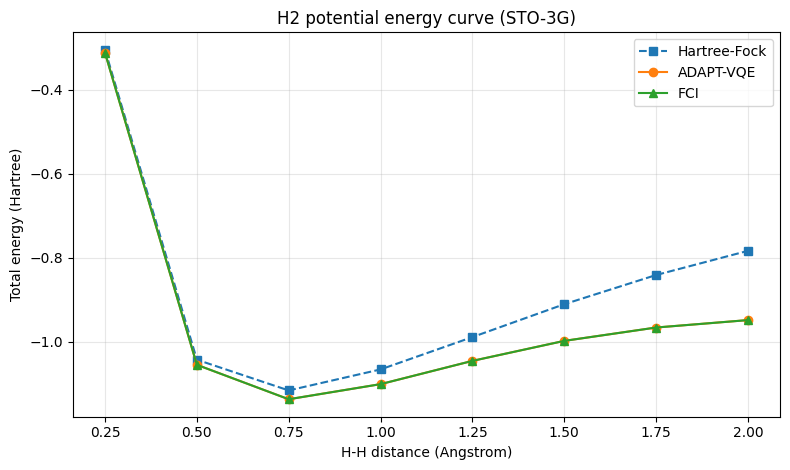

In [9]:
print("R[Å]   HF[Ha]        ADAPT[Ha]     FCI[Ha]        log10(err [kcal/mol])  Nop  Converged")
print("-" * 90)
for result in scan_results:
    print(
        f"{result['R']:4.2f}  {result['HF']: .9f}  {result['ADAPT']: .9f}  "
        f"{result['FCI']: .9f}      {result['error_kcal_mol']:9.5f}   "
        f"{result['n_operators']:2d}   {result['gradient_converged']}"
    )

for record, labels in zip(scan_results, selected_labels_by_distance):
    print(f"R={record['R']:.2f} Å: ", " -> ".join(labels) if labels else "No operators added")

R_values = np.array([row["R"] for row in scan_results])
E_hf = np.array([row["HF"] for row in scan_results])
E_adapt = np.array([row["ADAPT"] for row in scan_results])
E_fci = np.array([row["FCI"] for row in scan_results])

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(R_values, E_hf, "s--", label="Hartree-Fock")
ax.plot(R_values, E_adapt, "o-", label="ADAPT-VQE")
ax.plot(R_values, E_fci, "^-", label="FCI")
ax.set_xlabel("H-H distance (Angstrom)")
ax.set_ylabel("Total energy (Hartree)")
ax.set_title("H2 potential energy curve (STO-3G)")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## Summary

This tutorial explained the method proposed by [Grimsley et al. (2019)](https://www.nature.com/articles/s41467-019-10988-2) and showed how to implement it with Qamomile.
The key points are:

* ADAPT-VQE is a hybrid quantum–classical algorithm that selects operators using energy gradients and progressively grows the ansatz.
* In this implementation, the pool consists of generalized single and double fermionic excitation operators. The gradient for each candidate can be evaluated as the expectation value of its commutator with the Hamiltonian.
* Qamomile lets us express parameterized state preparation and expectation-value evaluation in a single quantum kernel. The same kernel can be used for both energy evaluation and operator selection.
* The $\mathrm{H}_2$ energy curve calculated with ADAPT-VQE agrees with the FCI results.
* These results are a small-scale validation using an ideal simulator. For more complex molecules or execution on real hardware, we need to consider the operator pool size, the cost of measuring gradients, circuit depth, and the effects of noise.